In [8]:
import torch
from torch.distributions import MultivariateNormal
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import torch.nn as nn
from torch.distributions import Uniform
import gc
import math
import time


plt.style.use(['science', 'notebook', 'grid'])
torch.set_default_device("cuda")
torch.manual_seed(0)

In [ ]:
d = 20
    # Image height and width
N = 10000
    # Number of samples
lr = .0008
    # Learning rate
steps = 100000
    # Number optimization iterations
M = 1
    # How many random vectors to estimate Hessian trace
B = 256
    # Mini batch size


mu = torch.ones(d ** 2,)

var = 2
L = 3
eps = .001

st1 = time.perf_counter()
def cov_comp(var, L):
    temp = torch.zeros(d ** 2, d ** 2)
    for n in range(temp.shape[0]):
            i_1 = n // d
            j_1 = n % d
            for m in range(temp.shape[1]):
                i_2 = m // d
                j_2 = m % d

                dist_squared = (i_1 - i_2) ** 2 + (j_1 - j_2) ** 2
                temp[m][n] = (var ** 2) * math.exp(- dist_squared / (2 * (L ** 2)))
    return temp

cov = cov_comp(var, L) + torch.eye(d ** 2,) * eps

et1 = time.perf_counter()

print(f"covariance computation time: {et1 - st1}")


dist = MultivariateNormal(mu, cov)
samples = dist.sample((N,)).detach().requires_grad_(True)

score_nn = nn.Linear(d ** 2, d ** 2, bias=True)
optimizer = torch.optim.Adam(score_nn.parameters(), lr=lr)


tr_dist = MultivariateNormal(torch.zeros(d **2, ), torch.eye(d ** 2, ))
def trace(score, data, i):
    tr_sample = tr_dist.sample((i,))
    vec_hess = torch.autograd.grad(outputs = score(data), inputs = data, grad_outputs=tr_sample, create_graph=True, retain_graph=True, is_grads_batched=True,)[0]
    return (tr_sample * vec_hess).sum(dim=1).mean()

    


     
def loss(score, data):
    vals = score(data)
    norm = 0.5 * vals.square().sum(dim=1)
    ttrace = torch.stack([trace(score, x,M) for x in data])
    return (ttrace + norm).mean()







storex = torch.zeros(steps // 100, )
storey = torch.zeros(steps // 100, )


for step in range(steps):
    stl = time.perf_counter()
        # Main training loop
    
    # st2 = time.perf_counter()
    indices = torch.randperm(N, device=samples.device)[:B]
    batch = samples[indices].detach().requires_grad_(True)
    loss_store = loss(score_nn, batch)
    # et2 = time.perf_counter()
    # print(f"Loss calc + trace: {et2-st2}")

    # st3 = time.perf_counter()
    optimizer.zero_grad()
    # et3 = time.perf_counter()
    # print(f"zero out grads calc: {et3-st3}")

            # Clear out gradients to not add from last loop
    # st3 = time.perf_counter()
    loss_store.backward()
    # et3 = time.perf_counter()
    # print(f"backprop calc: {et3-st3}")

        # Calculates gradients with respect to parameters in Adam
    # st4 = time.perf_counter()
    optimizer.step()
    # et4 = time.perf_counter()
    # print(f"grad decent calc: {et4-st4}")
    etl = time.perf_counter()
    if step % 100 == 0:
        print(f"loop time: {etl - stl}")



        # Calculated the Adam gradient descent
    if step % 100 == 0:
        print(f"Step: {step}, Loss: {loss_store}")
        storex[step // 100] = step
        storey[step // 100] = loss_store
    # if step == 1800:
    #     for param_group in optimizer.param_groups:
    #        param_group["lr"] = 0.00003
    # if step == 5000:
    #     for param_group in optimizer.param_groups:
    #         param_group["lr"] = 0.00008





test_set = dist.sample((N,)).requires_grad_()

def rmse(act,learned,x):
    return (((learned(x) - act(x)) ** 2).mean()) ** 0.5
    # Sqrt of mean squared error
        # .mean(): mean along all entries in tensor


def rel_rmse(act,learned,x):
    denom = ((act(x) ** 2).mean()) ** 0.5
        # Mean of actual squared
    return (rmse(act,learned,x) / denom) * 100
        # Used to make sqrt of MSE a unitless percen    tage for easy interpretability

def actual(x):
    return (torch.linalg.inv(cov) @ (mu - x).T).T

print(f"Error (rel-rmse): {rel_rmse(actual,score_nn,test_set)}")

storex = storex.detach().cpu().numpy()
storey = storey.detach().cpu().numpy()

plt.figure()
plt.imshow(actual(test_set)[0].reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
plt.colorbar(label="Real Score")
plt.axis("off")


plt.figure()
plt.imshow(score_nn(test_set)[0].reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
plt.colorbar(label="Test Score")
plt.axis("off")



plt.figure()
plt.title("Loss vs. Iterations")
plt.plot(storex, storey, 'o--', color='blue')
plt.legend(loc='upper right', fontsize=10)
plt.xlabel('iterations')
plt.ylabel('loss')


cov comp time: 437.410954699968
loop time: 0.7405367000028491
Step: 0, Loss: 2083.15234375
loop time: 0.45325900008901954
Step: 100, Loss: -160.8101348876953
loop time: 0.5721490000141785
Step: 200, Loss: -363.53912353515625
loop time: 0.5539348999736831
Step: 300, Loss: -558.7385864257812
loop time: 0.43284389993641526
Step: 400, Loss: -756.4679565429688
loop time: 0.548599399975501
Step: 500, Loss: -951.3948364257812
loop time: 0.5058187999529764
Step: 600, Loss: -1155.55859375
loop time: 0.51127739995718
Step: 700, Loss: -1355.127685546875
loop time: 0.4608775000087917
Step: 800, Loss: -1556.849853515625
loop time: 0.6149930000538006
Step: 900, Loss: -1747.4742431640625
loop time: 0.5137800999218598
Step: 1000, Loss: -1941.688232421875
loop time: 0.49175950000062585
Step: 1100, Loss: -2144.9375
loop time: 0.5177016999805346
Step: 1200, Loss: -2339.8310546875
loop time: 0.5291564000071958
Step: 1300, Loss: -2532.66015625
loop time: 0.5458927000872791
Step: 1400, Loss: -2734.994628906

AcceleratorError: CUDA error: unknown error
Search for `cudaErrorUnknown' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


Error (rel-rmse): 97.40386962890625


C:\Users\erics\AppData\Local\Temp\ipykernel_39560\3990208500.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right', fontsize=10)


(np.float64(-0.5), np.float64(49.5), np.float64(49.5), np.float64(-0.5))

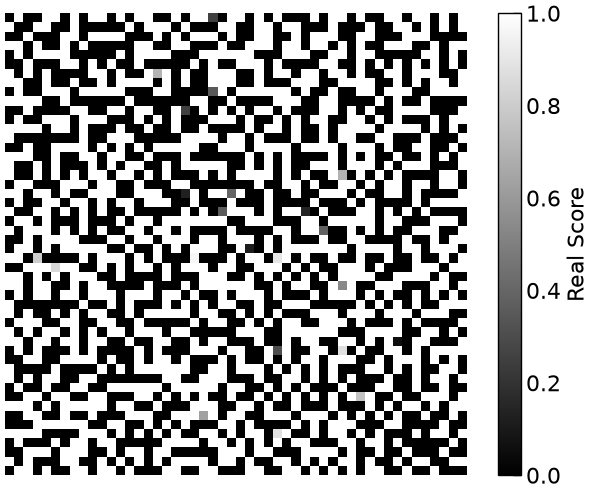

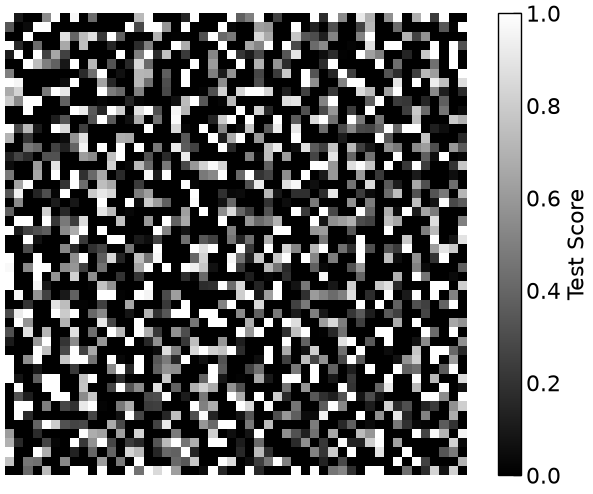

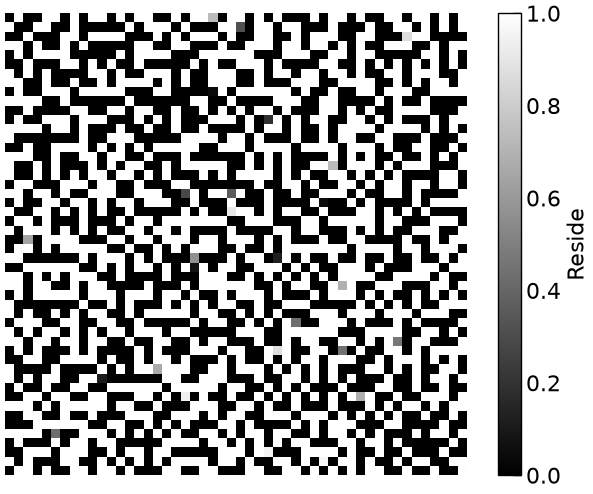

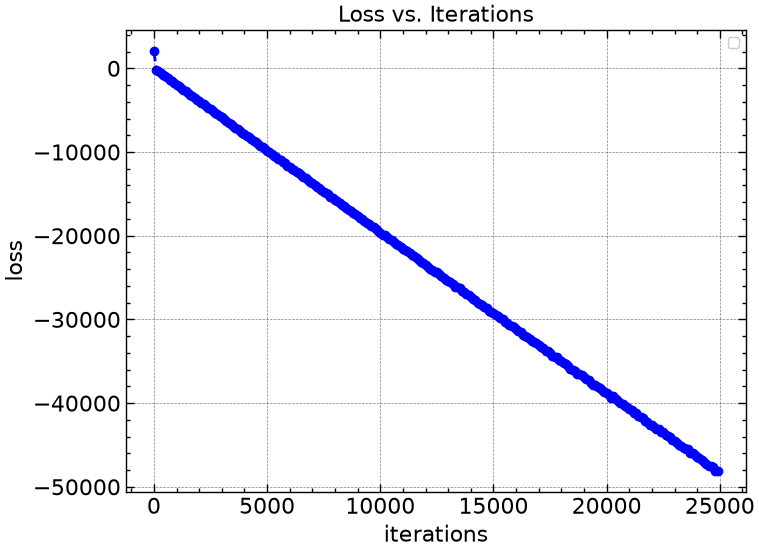

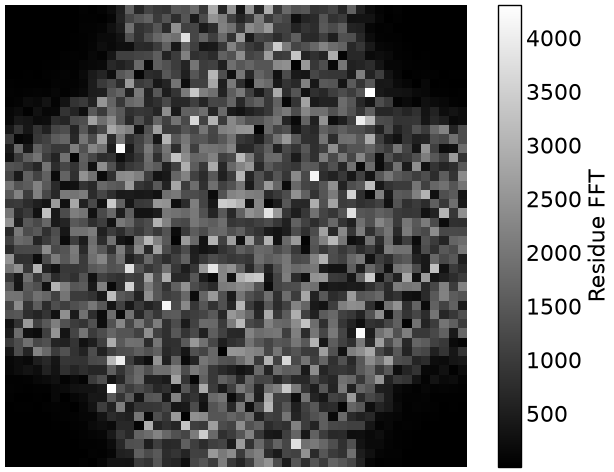

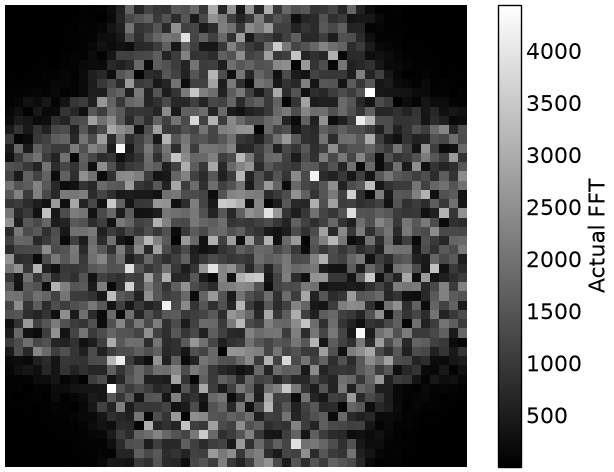

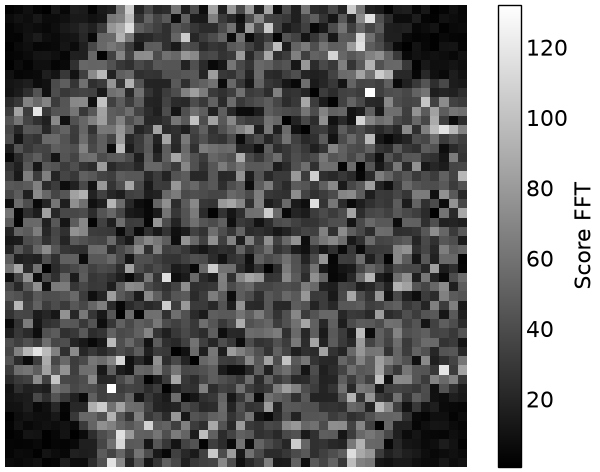

In [ ]:
fim_raw_res = (actual(test_set[0]) - score_nn(test_set[0])).reshape(d, d)
fim_res = torch.fft.fft2(fim_raw_res)

fim_raw_act = actual(test_set[0]).reshape(d, d)
fim_act = torch.fft.fft2(fim_raw_act)

fim_raw_score = score_nn(test_set[0]).reshape(d, d)
fim_score = torch.fft.fft2(fim_raw_score)

plt.figure()
plt.imshow(fim_res.abs().detach().cpu().numpy(), cmap="gray",)
plt.colorbar(label="Residue FFT")
plt.axis("off")


plt.figure()
plt.imshow(fim_act.abs().detach().cpu().numpy(), cmap="gray",)
plt.colorbar(label="Actual FFT")
plt.axis("off")


plt.figure()
plt.imshow(fim_score.abs().detach().cpu().numpy(), cmap="gray",)
plt.colorbar(label="Score FFT")
plt.axis("off")

temp = torch.zeros(i, )
    for j in range(i):
        vec_hess = torch.autograd.grad(outputs = score(data) @ tr_sample[j], inputs = data, create_graph=True, retain_graph=True,)[0]
        temp[j] = tr_sample[j] @ vec_hess
    return temp.mean()


    temp = torch.zeros(B, )
    for i in range(B, ):
        temp[i] =  0.5 * (torch.linalg.vector_norm(score(data[i]), ord=2)) ** 2 + trace(score, data[i], M)
    return temp.mean()